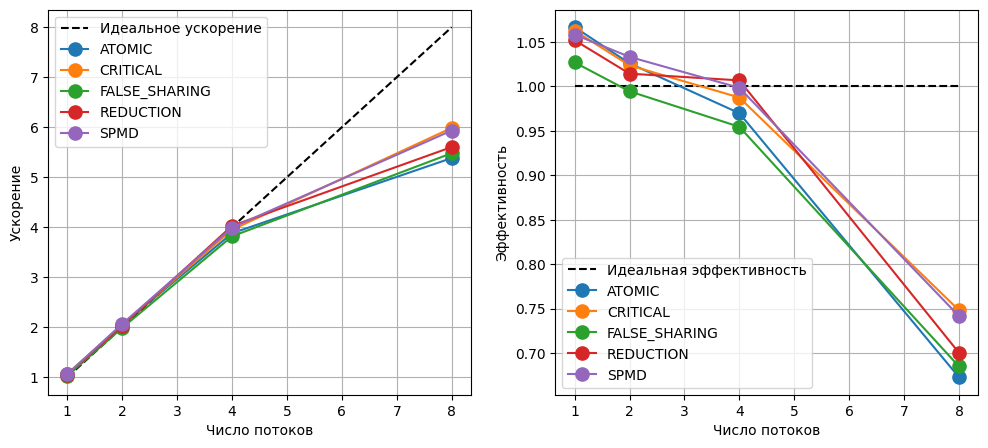

In [2]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# Получаем точный путь к твоему Рабочему столу на Маке
desktop_path = os.path.expanduser("~/Desktop")

# Явно прописываем полные пути к файлам на Рабочем столе
files = [
    os.path.join(desktop_path, "results/serial.csv"),
    os.path.join(desktop_path, "results/spmd.csv"),
    os.path.join(desktop_path, "results/reduction.csv"),
    os.path.join(desktop_path, "results/atomic.csv"),
    os.path.join(desktop_path, "results/critical.csv"),
    os.path.join(desktop_path, "results/false_sharing.csv"),
]

# 2. Читаем все файлы и склеиваем в одну таблицу
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# 3. Усредняем время по повторным запускам
stats = df.groupby(["method", "threads"], as_index=False)["time"].mean()

# 4. Базовое время: последовательная версия
serial = stats.loc[stats["method"] == "SERIAL", "time"]
t_serial = serial.iloc[0]

# 5. Ускорение и эффективность
stats["speedup"] = t_serial / stats["time"]
stats["efficiency"] = stats["speedup"] / stats["threads"]

# 6. График ускорения и эффективности
parallel = stats[stats["method"] != "SERIAL"]
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# - Ускорение 
threads = sorted(parallel["threads"].unique())
ax1.plot(threads, threads, "--", color="black", label="Идеальное ускорение")

for method, group in parallel.groupby("method"):
    ax1.plot(group["threads"], group["speedup"], linestyle="-", marker="o", markersize=9.5, label=method)

ax1.set_xlabel("Число потоков")
ax1.set_ylabel("Ускорение")
ax1.grid()
ax1.legend()

# - Эффективность 
max_threads = stats["threads"].max()
ax2.plot([1, max_threads], [1, 1], "--", color="black", label="Идеальная эффективность")

for method, group in parallel.groupby("method"):
    ax2.plot(group["threads"], group["efficiency"], linestyle="-", marker="o", markersize=9.5, label=method)

ax2.set_xlabel("Число потоков")
ax2.set_ylabel("Эффективность")
ax2.grid()
ax2.legend()

# Сохраняем картинку прямо на Рабочий стол
plt.savefig(os.path.join(desktop_path, "lab1_plots.png"), dpi=150)
plt.show()
